# EDA 05: chọn quy tắc xử lý dòng trùng timestamp

Với dòng trùng timestamp, nên giữ dòng đầu, lấy trung bình tọa độ hay bỏ cả nhóm? Các mục này **chọn quy tắc và ngưỡng lệch**, nên nằm ở giai đoạn tuning, chỉ trên nhóm validation. Notebook này **không chạy stay point**: D, T chưa chọn ở bước này (chọn ở notebook 09), nên không dùng stay point để chọn quy tắc. Phần mô tả (3.1–3.4) ở `notebooks/survey/01_data_quality.ipynb`.

| Mục | Nội dung |
|---|---|
| 1.1 | Lệch gần: có nên thay bằng điểm giữa nhóm không |
| 1.2 | Lệch xa: vì sao bỏ cả nhóm |
| 1.3 | Quy tắc và số dòng giữ / bỏ |

**Cách chạy.** Cần `python src/preprocess/convert_raw.py` trước. Mục này đọc lại file `.plt` gốc nên lần đầu quét nhóm validation mất vài phút (cache ở `data/interim/dup_scan_val/`). Code ở `src/eda/duplicates.py`. Mục đánh số riêng trong từng notebook (README có bảng mục và notebook).


> **Giai đoạn: TUNING (sau khi chia validation / test).** Chỉ đọc **nhóm validation** (`split.val_users()`). Không dùng nhóm test (D17, D19).
>
> Các số trong ô văn bản bên dưới là của lần chạy cũ (bản chia 06/11); cập nhật sau khi chạy lại.

In [9]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from eda.config import *          # dữ kiện từ tài liệu, mốc mô tả, bins (xem src/eda/config.py)
from eda.utils import pct, hist_quantile, qtable, fmt_s
from eda.scan import run
from eda import split

USERS_LIMIT = split.val_users()   # nhóm validation (D17); KHÔNG đặt None ở notebook tuning: sẽ đọc cả nhóm test

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

R = run(topics=[], users=USERS_LIMIT)
users, files, A = R.users, R.files, R.A

print(f"{len(users)} user, {len(files):,} file")

[20/115] đã đọc tới user 033 (2 giây)
[40/115] đã đọc tới user 063 (3 giây)
[60/115] đã đọc tới user 102 (4 giây)
[80/115] đã đọc tới user 132 (5 giây)
[100/115] đã đọc tới user 163 (8 giây)
[115/115] đã đọc tới user 180 (8 giây)
115 user, 12,376 file


## 1. Dòng trùng timestamp: chọn quy tắc

Dữ liệu dùng chung cho các mục dưới: bảng các nhóm trùng của nhóm validation.

In [10]:
import importlib
from eda import duplicates as dups
importlib.reload(dups)   # nạp lại code mới nếu kernel đã import bản cũ

REBUILD_DUP_SCAN = False   # True để đọc lại toàn bộ file .plt gốc (khoảng 10 phút)
# Cache cho nhóm validation (dup_scan_val); đổi USERS_LIMIT thì xoá thư mục đó
PU, EX = dups.scan_all_users(users=USERS_LIMIT, cache_dir=ROOT / "data" / "interim" / "dup_scan_val",
                             rebuild=REBUILD_DUP_SCAN)
EX["user"] = EX["user"].astype(str)
n_all, n_extra = int(PU["n_rows"].sum()), len(EX)

ov = pd.DataFrame({"số dòng": {
    "tổng dòng thô": n_all,
    "dòng thuộc nhóm trùng": int(PU["n_in_groups"].sum()),
    "số nhóm trùng (timestamp bị trùng)": int(PU["n_groups"].sum()),
    "dòng thừa": n_extra,
}})
ov["% tổng dòng thô"] = (ov["số dòng"] / n_all * 100).round(2)
print(f"User có dòng trùng: {(PU['n_extra'] > 0).sum()} / {len(PU)}")
ov

User có dòng trùng: 39 / 87


,số dòng,% tổng dòng thô
tổng dòng thô,13107562,100.00
dòng thuộc nhóm trùng,175590,1.34
số nhóm trùng (timestamp bị trùng),60998,0.47
dòng thừa,114592,0.87


,dòng thừa,dòng thừa % (của user),trùng hoàn toàn %,cỡ nhóm,% tổng dòng thừa (cộng dồn)
user,,,,,
165,68281,52.2,29.2,5,59.6
179,14084,8.3,100.0,2,71.9
167,9992,1.6,99.9,2,80.6
126,9846,2.3,100.0,2,89.2
125,5944,6.2,100.0,2,94.4
067,3130,0.8,0.9,5,97.1
007,1686,1.9,100.0,2,98.6
096,1187,0.5,99.9,2,99.6


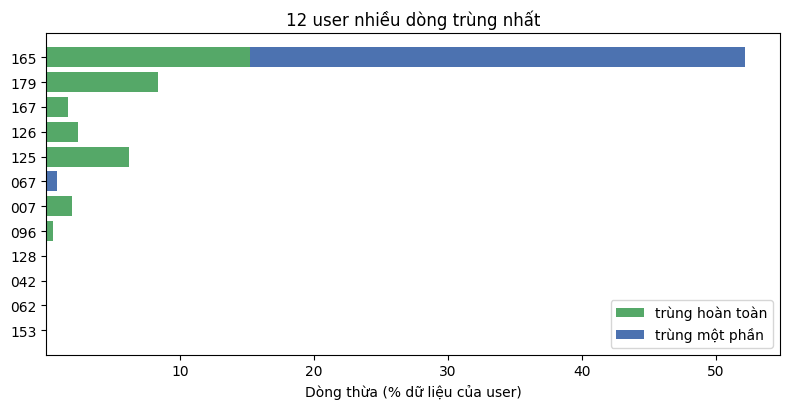

In [11]:
ut = PU[PU["n_extra"] > 0].copy()
ut["dòng thừa % (của user)"] = ut["n_extra"] / ut["n_rows"] * 100
ut["trùng hoàn toàn %"] = EX.groupby("user")["identical"].mean() * 100
ut["cỡ nhóm"] = EX.groupby("user")["group_size"].median().astype(int)
ut = ut.sort_values("n_extra", ascending=False)
ut["% tổng dòng thừa (cộng dồn)"] = ut["n_extra"].cumsum() / n_extra * 100
display(ut.head(8)[["n_extra", "dòng thừa % (của user)", "trùng hoàn toàn %", "cỡ nhóm", "% tổng dòng thừa (cộng dồn)"]]
        .rename(columns={"n_extra": "dòng thừa"}).round(1))

top = ut.head(12).iloc[::-1]
full = top["dòng thừa % (của user)"] * top["trùng hoàn toàn %"] / 100
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.index, full, color="#55a868", label="trùng hoàn toàn")
ax.barh(top.index, top["dòng thừa % (của user)"] - full, left=full, color="#4c72b0", label="trùng một phần")
ax.set_xlabel("Dòng thừa (% dữ liệu của user)")
ax.set_title("12 user nhiều dòng trùng nhất")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 1.1 Lệch gần: có nên thay bằng điểm giữa nhóm không

Với dòng thừa khác lat / lon: cách dòng đầu nhóm bao xa? Mốc tham chiếu thử: ở 300 km/h (ngưỡng tốc độ thử, sẽ xét ở notebook 06), 1 giây đi được khoảng **83 m**. Lệch trong mốc này có thể là do ghi nhiều lần trong một giây; lệch xa hơn thì ít nhất một dòng sai (mục 1.2).

,dòng thừa,% dòng khác tọa độ,% cộng dồn
cách dòng đầu nhóm,,,
≤ 1 m,36667,70.731,70.731
1–10 m,14703,28.362,99.093
10–83 m,272,0.525,99.618
> 83 m,198,0.382,100.000


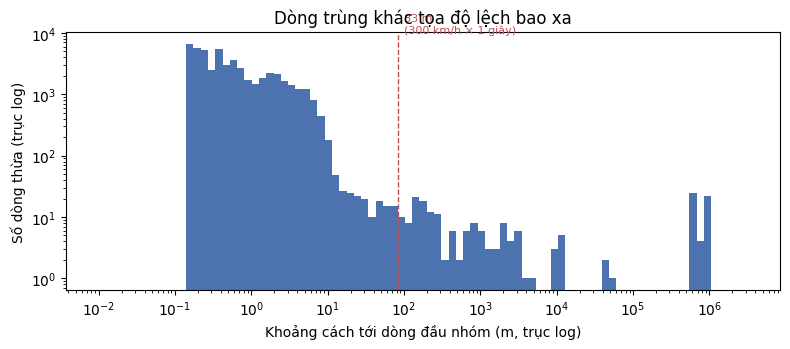

In [12]:
dc = EX[~(EX["eq_lat"] & EX["eq_lon"])]
bins = [0, 1, 10, dups.SAME_SECOND_MAX_M, np.inf]
cut = pd.cut(dc["d_first_m"], bins, labels=["≤ 1 m", "1–10 m", "10–83 m", "> 83 m"], include_lowest=True)
dt = cut.value_counts(sort=False).rename("dòng thừa").to_frame()
dt["% dòng khác tọa độ"] = dt["dòng thừa"] / len(dc) * 100
dt["% cộng dồn"] = dt["% dòng khác tọa độ"].cumsum()
dt.index.name = "cách dòng đầu nhóm"
display(dt.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(dc["d_first_m"].clip(lower=0.01), bins=np.logspace(-2, 6.5, 90), color="#4c72b0")
ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(dups.SAME_SECOND_MAX_M, color="#c44e52", ls="--", lw=1)
ax.text(dups.SAME_SECOND_MAX_M * 1.2, 1e4, "83 m\n(300 km/h × 1 giây)", fontsize=8, color="#c44e52")
ax.set_xlabel("Khoảng cách tới dòng đầu nhóm (m, trục log)")
ax.set_ylabel("Số dòng thừa (trục log)")
ax.set_title("Dòng trùng khác tọa độ lệch bao xa")
plt.tight_layout()
plt.show()

**Thay dòng đầu bằng tâm nhóm (trung bình lat, lon) thì điểm dời đi bao xa?** Đo trên 3 user nhiều trùng nhất. Để so sánh: cột cuối là quãng đi giữa hai giây liên tiếp.

In [13]:
TOP3 = list(ut.index[:3])
rows = {}
for u in TOP3:
    raw = dups.load_user_raw(u)
    cs = dups.center_shift(raw)
    p = raw[raw["ts"].notna()].sort_values(["ts", "file", "row"], kind="stable").drop_duplicates("ts")
    step = pd.Series(dups.haversine_m(p["lat_f"].to_numpy()[:-1], p["lon_f"].to_numpy()[:-1],
                                      p["lat_f"].to_numpy()[1:], p["lon_f"].to_numpy()[1:]))
    step = step[np.diff(p["ts"].to_numpy()).astype("timedelta64[s]").astype(int) == 1]
    rows[u] = {"các dòng cách tâm nhóm, TB (m)": cs["spread_m"].mean(),
               "dòng đầu cách tâm nhóm, TB (m)": cs["shift_m"].mean(),
               "dòng đầu cách tâm nhóm, p95 (m)": cs["shift_m"].quantile(0.95),
               "quãng đi trong 1 giây, TB (m)": step.mean()}
pd.DataFrame(rows).T.round(2)

,"các dòng cách tâm nhóm, TB (m)","dòng đầu cách tâm nhóm, TB (m)","dòng đầu cách tâm nhóm, p95 (m)","quãng đi trong 1 giây, TB (m)"
165,0.54,0.45,2.08,2.15
179,0.00,0.00,0.00,13.53
167,0.03,0.03,0.00,7.66


**Kết quả:** _chưa có. Chạy lại notebook trên nhóm validation của bản chia mới rồi ghi kết luận ở đây._ Đọc: lệch bao xa so với dòng đầu, và thay dòng đầu bằng tâm nhóm thì điểm dời bao nhiêu so với quãng đi trong 1 giây.

### 1.2 Lệch xa (> 83 m): vì sao bỏ cả nhóm

Với mỗi nhóm có dòng cách dòng đầu hơn 83 m, so từng dòng với điểm liền trước và liền sau trên quỹ đạo (timestamp khác gần nhất). Dòng có tổng khoảng cách tới hai điểm đó nhỏ nhất là dòng "khớp quỹ đạo". Nếu dòng đầu thường là dòng khớp thì giữ dòng đầu là đủ; nếu không thì không có căn cứ chọn dòng nào.

In [14]:
far_users = sorted(EX.loc[EX["d_first_m"] > dups.SAME_SECOND_MAX_M, "user"].unique())
CF = pd.concat([dups.conflict_groups(dups.load_user_raw(u)).assign(user=u) for u in far_users])
GR = dups.group_rules(EX)
n_r4_rows = int(GR.loc[GR["quy tắc"] == "R4", "n_rows"].sum())
display(pd.Series({
    "số nhóm lệch xa": len(CF),
    "số user": len(far_users),
    "số dòng trong các nhóm đó": n_r4_rows,
    "% tổng dòng thô": round(n_r4_rows / n_all * 100, 4),
    "dòng đầu là dòng khớp quỹ đạo (% nhóm)": round(CF["first_is_best"].mean() * 100, 1),
}).to_frame("giá trị"))
print("Ví dụ user 062: hai quỹ đạo cách nhau khoảng 850 km ghi xen kẽ trong cùng một file")
display(CF[CF["user"] == "062"].head(6)[["n_rows", "max_d_first_m", "first_is_best", "d_first_prev_m",
                                         "ở đâu (file:số dòng)"]].round(0))

,giá trị
số nhóm lệch xa,129.0000
số user,11.0000
số dòng trong các nhóm đó,362.0000
% tổng dòng thô,0.0028
dòng đầu là dòng khớp quỹ đạo (% nhóm),41.1000


Ví dụ user 062: hai quỹ đạo cách nhau khoảng 850 km ghi xen kẽ trong cùng một file


,n_rows,max_d_first_m,first_is_best,d_first_prev_m,ở đâu (file:số dòng)
ts,,,,,
2008-09-26 09:35:04,2,852278.0,False,852232.0,20080926000623.plt:7523
2008-09-26 09:35:19,2,851968.0,False,851936.0,20080926000623.plt:7531
2008-09-26 09:35:29,2,851707.0,True,21.0,20080926000623.plt:7538
2008-09-26 09:35:39,2,851438.0,False,851421.0,20080926000623.plt:7545
2008-09-26 09:35:49,2,851169.0,True,22.0,20080926000623.plt:7552
2008-09-26 09:35:59,2,850887.0,True,21.0,20080926000623.plt:7559


**Kết quả:** _chưa có. Chạy lại notebook trên nhóm validation của bản chia mới rồi ghi kết luận ở đây._ Đọc: dòng đầu có khớp quỹ đạo thường xuyên không, có biết dòng nào sai không, và cái giá của việc bỏ cả nhóm.

### 1.3 Quy tắc xử lý và số dòng giữ / bỏ

Các quy tắc ứng viên (điền kết luận sau khi chạy 3.4–3.5):

| Quy tắc | Điều kiện (so với dòng đầu nhóm cùng timestamp) | Xử lý ứng viên |
|---|---|---|
| R1 | Giống mọi cột (trùng hoàn toàn) | Giữ dòng đầu |
| R2 | Cùng lat, lon; chỉ khác độ cao | Giữ dòng đầu (độ cao không dùng) |
| R3 | Khác tọa độ, lệch trong mốc ngưỡng | giữ dòng đầu hay lấy trung bình: chưa chọn |
| R4 | Có dòng lệch quá mốc ngưỡng | bỏ cả nhóm hay giữ: chưa chọn; mốc ngưỡng chưa chọn |
| R5 | File giống hệt ở nhiều user | Dùng để chia validation/test theo cụm user (D17) |

Mỗi nhóm được xếp theo dòng "tệ nhất" của nó.


So với chỉ giữ dòng đầu (A3 hiện tại, bỏ 114,592 dòng): bỏ thêm 129 dòng


,xử lý,số_nhóm,số_dòng,giữ_lại,bỏ_đi,% tổng dòng thô,giữ lại % tổng,bỏ đi % tổng,bỏ đi % dòng bị bỏ,vì sao
quy tắc,,,,,,,,,,
không trùng,giữ nguyên,0,12931972,12931972,0,98.660,98.660,0.0000,0.00,timestamp chỉ có một dòng
R1,gộp về dòng đầu,46191,102576,46191,56385,0.783,0.352,0.4302,49.15,"giống mọi cột, bỏ dòng lặp không mất thông tin (notebook 01, mục 3.2)"
R2,gộp về dòng đầu,0,0,0,0,0.000,0.000,0.0000,0.00,"cùng tọa độ, chỉ khác độ cao; bài toán không dùng độ cao (notebook 01, mục 3.2)"
R3,gộp về dòng đầu,14678,72652,14678,57974,0.554,0.112,0.4423,50.53,"lệch ≤ 83 m, ghi nhiều lần trong 1 giây; dòng đầu cách tâm nhóm < 1 m (mục 1.1)"
R4,xóa cả nhóm,129,362,0,362,0.003,0.000,0.0028,0.32,lệch > 83 m (> 300 km/h); chắc chắn có dòng sai nhưng không biết dòng nào (mục 1.2)
tổng,,60998,13107562,12992841,114721,100.000,99.125,0.8752,100.00,


,số_dòng,giữ_lại,bỏ_đi,% tổng dòng thô,bỏ đi % tổng
xử lý,,,,,
giữ nguyên,12931972,12931972,0,98.6604,0.0000
gộp về dòng đầu,175228,60869,114359,1.3368,0.8725
xóa cả nhóm,362,0,362,0.0028,0.0028


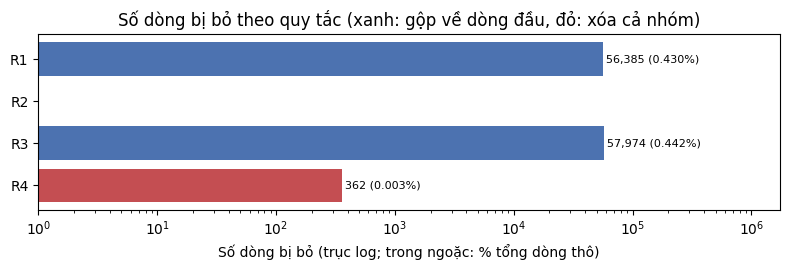

In [15]:
LOẠI = {
    "không trùng": ("giữ nguyên", "timestamp chỉ có một dòng"),
    "R1": ("gộp về dòng đầu", "giống mọi cột, bỏ dòng lặp không mất thông tin (notebook 01, mục 3.2)"),
    "R2": ("gộp về dòng đầu", "cùng tọa độ, chỉ khác độ cao; bài toán không dùng độ cao (notebook 01, mục 3.2)"),
    "R3": ("gộp về dòng đầu", "lệch ≤ 83 m, ghi nhiều lần trong 1 giây; dòng đầu cách tâm nhóm < 1 m (mục 1.1)"),
    "R4": ("xóa cả nhóm", "lệch > 83 m (> 300 km/h); chắc chắn có dòng sai nhưng không biết dòng nào (mục 1.2)"),
}
rt = GR.groupby("quy tắc").agg(số_nhóm=("n_rows", "size"), số_dòng=("n_rows", "sum"),
                               giữ_lại=("kept", "sum"), bỏ_đi=("removed", "sum"))
n_single = n_all - int(rt["số_dòng"].sum())
rt.loc["không trùng"] = [0, n_single, n_single, 0]
rt = rt.reindex(list(LOẠI)).fillna(0).astype(int)   # quy tắc không có nhóm nào (vd R2 ở nhóm validation) ghi 0
rt.insert(0, "xử lý", [LOẠI[k][0] for k in rt.index])
rt.loc["tổng"] = ["", *rt[["số_nhóm", "số_dòng", "giữ_lại", "bỏ_đi"]].sum()]
rt["% tổng dòng thô"] = rt["số_dòng"] / n_all * 100
rt["giữ lại % tổng"] = rt["giữ_lại"] / n_all * 100
rt["bỏ đi % tổng"] = rt["bỏ_đi"] / n_all * 100
rt["bỏ đi % dòng bị bỏ"] = rt["bỏ_đi"] / rt.loc["tổng", "bỏ_đi"] * 100
rt["vì sao"] = [LOẠI[k][1] if k in LOẠI else "" for k in rt.index]
print(f"So với chỉ giữ dòng đầu (A3 hiện tại, bỏ {n_extra:,} dòng): bỏ thêm {int(rt.loc['tổng', 'bỏ_đi']) - n_extra:,} dòng")
with pd.option_context("display.max_colwidth", 120):
    display(rt.round({"% tổng dòng thô": 3, "giữ lại % tổng": 3, "bỏ đi % tổng": 4, "bỏ đi % dòng bị bỏ": 2}))

# Tổng hợp theo cách xử lý: bao nhiêu % dữ liệu giữ nguyên, gộp, xóa
by = rt.drop("tổng").groupby("xử lý", sort=False)[["số_dòng", "giữ_lại", "bỏ_đi"]].sum()
by["% tổng dòng thô"] = by["số_dòng"] / n_all * 100
by["bỏ đi % tổng"] = by["bỏ_đi"] / n_all * 100
display(by.round(4))

fig, ax = plt.subplots(figsize=(8, 2.8))
x = rt.drop(["tổng", "không trùng"])
bars = ax.barh(x.index[::-1], x["bỏ_đi"].iloc[::-1], color=["#c44e52" if k == "R4" else "#4c72b0" for k in x.index[::-1]])
ax.bar_label(bars, labels=[f"{n:,} ({p:.3f}%)" for n, p in zip(x["bỏ_đi"].iloc[::-1], x["bỏ đi % tổng"].iloc[::-1])],
             fontsize=8, padding=2)
ax.set_xscale("log")
ax.set_xlim(1, x["bỏ_đi"].max() * 30)
ax.set_xlabel("Số dòng bị bỏ (trục log; trong ngoặc: % tổng dòng thô)")
ax.set_title("Số dòng bị bỏ theo quy tắc (xanh: gộp về dòng đầu, đỏ: xóa cả nhóm)")
plt.tight_layout()
plt.show()

**Quyết định:** _chưa chọn. Ghi sau khi chạy xong các bảng ở trên._